# Plotting overview of domain geometry used in simulations

In [1]:
import jax.numpy as jnp
import matplotlib.colors
import sys
sys.path.append('../../')

from utils.geometry import Geom
from utils import plotting_utils

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [2]:
dz = 0.025       # grid spacing [m]
dx = 0.025    # grid spacing [m]
ztot = 1       # height of the cross-sction [m]
xtot = 10   # length of the domain [m]
slope = -0.1   # slope of the domain [-]

geom = Geom(dx, dz, 0, xtot, -ztot, 0, slope)  # geometry object
geom.create_grid()

===============   Creating grid   =============== 
DONE: created grid with  400 x 40 cells.


In [3]:
# # Sandy soil parameters
soil_type = {1:{}, 2:{}}
soil = jnp.ones((geom.nz,geom.nx))  # soil type array
soil_type[1]["alpha"] = 14.5                        # van Genuchten alpha [1/m]
soil_type[1]["Ksat"] = 8.25e-5                      # saturated hydraulic conductivity [m/s]
soil_type[1]["N"] = 2.68                            # van Genuchten N [-]
soil_type[1]["Theta_r"] = 0.045                     # minimum volumetric water content [-]
soil_type[1]["Theta_s"] = 0.43                      # maximum volumetric water content [-]

# # Loamy soil parameters
indices = jnp.where((geom.Z<=-.25+slope*geom.X) & (geom.Z>=-.5+slope*geom.X))
soil = soil.at[indices].set(2)
soil_type[2]["alpha"] = 1.6
soil_type[2]["Ksat"] = 6.94e-7
soil_type[2]["N"] = 1.37
soil_type[2]["Theta_r"] = 0.034
soil_type[2]["Theta_s"] = 0.46

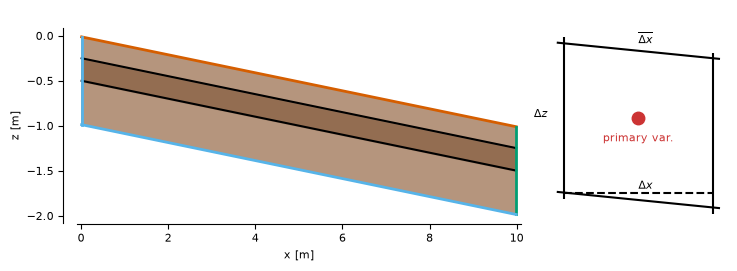

In [4]:
sand = (160/225, 149/255, 125/255)
loam = (130/225, 109/255, 81/255)
cmap = matplotlib.colors.ListedColormap([sand,loam])
fig,ax = plotting_utils.plot_domain(geom.X,geom.Z, soil, colormap=cmap)
fig.savefig("../../figures/method/domain.png", dpi=300, transparent=False)